# Climate Classes from Cooling Systems

<div dir="rtl">

اطلاعات اقلیم در دیتاست نیست، ولی نوع سیستم سرمایشی خانه‌ها نشانه‌ی خوبی از آن است: در هوای شرجی کولر آبی کار نمی‌کند و مردم اسپلیت می‌گذارند. شهرها را با همین نشانه به سه گروه اقلیمی تقسیم می‌کنیم و بعد بررسی می‌کنیم که آیا ارزش سرمایش مرکزی در همه‌ی اقلیم‌ها یکسان است یا نه.

</div>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

df = pd.read_parquet('divar_clean.parquet', columns=['cat3_slug', 'city_slug', 'has_cooling_system', 'price_per_m2'])

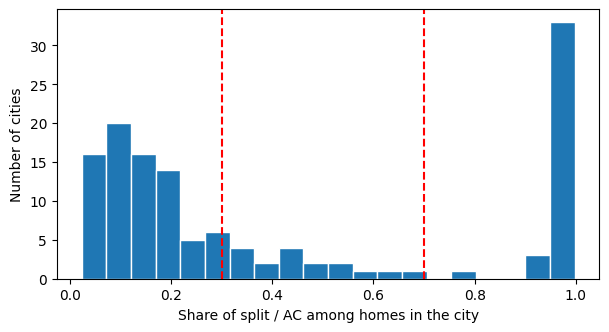

In [2]:
homes = df[df['cat3_slug'].str.startswith(('apartment', 'house'), na=False)]
homes = homes[homes['has_cooling_system'].isin(['split', 'air_conditioner', 'water_cooler'])]

city = homes.groupby('city_slug')['has_cooling_system'].agg(
    ads='size', split_share=lambda s: (s != 'water_cooler').mean())
city = city[city['ads'] >= 150]   # too few ads -> share is not reliable

plt.figure(figsize=(7, 3.5))
plt.hist(city['split_share'], bins=20, edgecolor='white')
plt.axvline(0.3, color='red', ls='--')
plt.axvline(0.7, color='red', ls='--')
plt.xlabel('Share of split / AC among homes in the city')
plt.ylabel('Number of cities')
plt.show()

<div dir="rtl">

بیشتر شهرها یا تقریباً همه کولر آبی دارند یا تقریباً همه اسپلیت، و تعداد کمی بین این دو هستند. برای همین مرزها را ۰.۳ و ۰.۷ گذاشتیم:

- `dry`: سهم اسپلیت تا ۰.۳
- `mixed`: بین ۰.۳ و ۰.۷
- `humid`: بیشتر از ۰.۷

</div>

In [3]:
city['climate'] = pd.cut(city['split_share'], [0, 0.3, 0.7, 1],
                         labels=['dry', 'mixed', 'humid'], include_lowest=True)
df['climate'] = df['city_slug'].map(city['climate'])

print(city['climate'].value_counts())
city.sort_values('ads', ascending=False).groupby('climate', observed=True).head(4).sort_values('climate')

climate
dry      75
humid    37
mixed    19
Name: count, dtype: int64


,ads,split_share,climate
city_slug,,,
tehran,72390,0.133168,dry
karaj,23152,0.169100,dry
isfahan,13969,0.143675,dry
kermanshah,6846,0.138183,dry
mashhad,27838,0.415367,mixed
andisheh-new-town,12729,0.462566,mixed
shiraz,11207,0.310163,mixed
qom,6091,0.352159,mixed
rasht,4700,0.991277,humid


## Is central cooling worth more everywhere?

<div dir="rtl">

برای اینکه قیمت شهرهای مختلف با هم قاطی نشود، قیمت هر متر هر آپارتمان را بر میانه‌ی شهر خودش تقسیم می‌کنیم (`relative_price`). مثلاً ۱.۲ یعنی ۲۰٪ گران‌تر از آپارتمان معمولی همان شهر.

</div>

In [4]:
apt = df[df['cat3_slug'] == 'apartment-sell'].copy()
apt['relative_price'] = apt['price_per_m2'] / apt.groupby('city_slug')['price_per_m2'].transform('median')
apt['cooling'] = apt['has_cooling_system'].map({
    'water_cooler': 'evaporative', 'split': 'split', 'air_conditioner': 'split',
    'duct_split': 'central', 'fan_coil': 'central'})

apt.pivot_table(index='climate', columns='cooling', values='relative_price',
                aggfunc='median', observed=True).round(2)

cooling,central,evaporative,split
climate,,,
dry,1.65,0.93,1.07
mixed,1.55,0.89,1.10
humid,1.09,0.94,1.05


<div dir="rtl">

فرض صفر: در هر اقلیم، قیمت نسبی آپارتمان‌های دارای سرمایش مرکزی با آپارتمان‌های دارای اسپلیت فرقی ندارد. آزمون Mann-Whitney را جداگانه برای هر اقلیم انجام می‌دهیم. چون حجم نمونه زیاد است، علاوه بر p-value به اندازه‌ی اثر (r) هم نگاه می‌کنیم.

</div>

In [5]:
rows = []
for climate in ['dry', 'mixed', 'humid']:
    part = apt[apt['climate'] == climate]
    central = part.loc[part['cooling'] == 'central', 'relative_price'].dropna()
    split = part.loc[part['cooling'] == 'split', 'relative_price'].dropna()
    u, p = mannwhitneyu(central, split)
    r = 2 * u / (len(central) * len(split)) - 1
    rows.append([climate, len(central), len(split), p, round(r, 2)])

pd.DataFrame(rows, columns=['climate', 'n_central', 'n_split', 'p_value', 'r'])

,climate,n_central,n_split,p_value,r
0,dry,15181,14735,0.000000e+00,0.51
1,mixed,2414,18198,2.996123e-229,0.40
2,humid,1985,9406,1.846814e-04,0.05


<div dir="rtl">

در اقلیم خشک و بینابینی فرض صفر رد می‌شود و اثر متوسط است: آپارتمان‌هایی که سرمایش مرکزی دارند به‌وضوح گران‌ترند. ولی در اقلیم شرجی، با اینکه p-value کوچک است، r نزدیک صفر است و عملاً تفاوتی وجود ندارد.

پس ارزش یک امکان به اقلیم بستگی دارد. سرمایش مرکزی در شهرهای خشک یک امتیاز قیمتی است، ولی در شهرهای شرجی خریدار بابت آن پول بیشتری نمی‌دهد. این نکته هم برای سازنده‌ها (که چه سیستمی نصب کنند) مهم است و هم برای سیستم توصیه‌گر (که این امکان را در کدام شهرها برجسته کند).

</div>